# Cost Sensitivity and Recommendation Robustness

The scenario model uses illustrative electricity prices, procurement premiums, and capital costs. This notebook tests whether the cost case for Efficiency + Clean Procurement remains reasonable when those assumptions change.

I use one-way sensitivity analysis: one input is changed while all other assumptions remain at their central values. This approach does not represent every possible future, but it shows which assumptions have the greatest influence on the recommendation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import Markdown, display


ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)


display_names = {
    "Grid Baseline": "Baseline",
    "Efficiency + Clean Procurement": (
        "Efficiency + Clean Procurement"
    ),
    "Efficiency + Flexible Load + Battery": (
        "Efficiency + Flexibility + Battery"
    ),
}


def format_scenario_table(dataframe):
    """Return a presentation copy with shorter scenario names."""
    formatted = dataframe.copy()

    formatted["scenario"] = (
        formatted["scenario"]
        .map(display_names)
        .fillna(formatted["scenario"])
    )

    return formatted

## Load the central-case inputs

This notebook uses the same hourly facility profile, scenario assumptions, and eGRID emissions factor as the main scenario model. Loading the processed files rather than recreating the inputs keeps the sensitivity analysis consistent with the earlier notebooks.

In [2]:
facility = pd.read_csv(
    PROCESSED / "facility_load_hourly.csv",
    parse_dates=["timestamp"],
)

scenarios = pd.read_csv(
    PROCESSED / "scenario_assumptions.csv"
)

co2_factor = float(
    pd.read_csv(
        PROCESSED / "egrid_emissions_factor.csv"
    ).loc[0, "co2_lb_per_mwh"]
)


expected_scenarios = {
    "Grid Baseline",
    "Efficiency + Clean Procurement",
    "Efficiency + Flexible Load + Battery",
}

missing_scenarios = (
    expected_scenarios
    - set(scenarios["scenario"])
)

if missing_scenarios:
    raise ValueError(
        "The scenario assumptions file is missing: "
        f"{sorted(missing_scenarios)}"
    )


assert len(facility) == 8760
assert facility["timestamp"].is_unique
assert facility["load_mw"].notna().all()
assert len(scenarios) == 3
assert co2_factor > 0


print(
    f"Loaded {len(facility):,} hourly observations "
    f"and {len(scenarios)} scenarios."
)

print(
    f"Regional emissions factor: "
    f"{co2_factor:,.3f} lb CO2/MWh"
)

display(
    format_scenario_table(scenarios)
)

Loaded 8,760 hourly observations and 3 scenarios.
Regional emissions factor: 593.419 lb CO2/MWh


,scenario,efficiency_pct,renewable_share,premium_usd_per_mwh,flex_peak_pct,battery_mw,battery_mwh,capex_usd
0,Baseline,0.00,0.0,0.0,0.00,0,0,0
1,Efficiency + Clean Procurement,0.08,0.8,6.0,0.00,0,0,20000000
2,Efficiency + Flexibility + Battery,0.05,0.4,6.0,0.05,20,80,45000000


## Reuse the scenario model

The following functions reproduce the calculation used in the main scenario notebook. Efficiency reduces electricity use, flexible operations shift some demand to lower-load hours, and the battery performs simplified monthly peak shaving.

The same cost and emissions equations are used for every sensitivity case. Only the assumption explicitly being tested is changed.

In [3]:
def adjusted_load(
    base_load,
    efficiency_pct,
    flex_peak_pct,
):
    """Apply efficiency and operational load shifting."""
    load = base_load.astype(float).copy()

    # Efficiency reduces demand in every hour.
    load *= 1 - efficiency_pct

    # Flexibility shifts electricity out of the top 5% of hours.
    if flex_peak_pct > 0:
        peak_mask = load >= load.quantile(0.95)

        shifted_mwh = (
            load.loc[peak_mask]
            * flex_peak_pct
        )

        load.loc[peak_mask] -= shifted_mwh

        offpeak_mask = (
            load <= load.quantile(0.50)
        )

        load.loc[offpeak_mask] += (
            shifted_mwh.sum()
            / offpeak_mask.sum()
        )

    return load


def apply_battery_peak_shaving(
    load,
    timestamps,
    battery_mw,
    battery_mwh,
    round_trip_efficiency=0.90,
):
    """Apply the simplified monthly battery proxy."""
    result = load.astype(float).copy()

    if battery_mw <= 0 or battery_mwh <= 0:
        return result

    timestamp_series = pd.Series(
        pd.to_datetime(timestamps).to_numpy(),
        index=result.index,
    )

    month_labels = (
        timestamp_series.dt.to_period("M")
    )

    for month in month_labels.unique():
        month_index = month_labels.index[
            month_labels == month
        ]

        monthly_load = result.loc[month_index]

        discharge_duration_hours = int(
            np.ceil(battery_mwh / battery_mw)
        )

        discharge_hours = (
            monthly_load
            .nlargest(discharge_duration_hours)
            .index
        )

        remaining_energy_mwh = battery_mwh
        discharged_energy_mwh = 0.0

        for hour_index in discharge_hours:
            discharge_mwh = min(
                battery_mw,
                remaining_energy_mwh,
                result.loc[hour_index],
            )

            result.loc[hour_index] -= discharge_mwh
            remaining_energy_mwh -= discharge_mwh
            discharged_energy_mwh += discharge_mwh

        recharge_energy_mwh = (
            discharged_energy_mwh
            / round_trip_efficiency
        )

        possible_charge_hours = (
            result.loc[month_index]
            .drop(index=discharge_hours)
        )

        number_of_charge_hours = min(
            100,
            len(possible_charge_hours),
        )

        charge_hours = (
            possible_charge_hours
            .nsmallest(number_of_charge_hours)
            .index
        )

        charge_mw = (
            recharge_energy_mwh
            / number_of_charge_hours
        )

        if charge_mw > battery_mw:
            raise ValueError(
                "Required charging power exceeds "
                "the battery power rating."
            )

        result.loc[charge_hours] += charge_mw

    return result


def capital_recovery_factor(
    rate=0.07,
    years=15,
):
    """Calculate the annual capital recovery factor."""
    return (
        rate * (1 + rate) ** years
        / ((1 + rate) ** years - 1)
    )


def evaluate_scenario(
    base_df,
    row,
    co2_lb_per_mwh,
    base_energy_price=70.0,
    demand_charge_kw_month=12.0,
    round_trip_efficiency=0.90,
):
    """Calculate cost, peak demand, energy, and emissions."""
    load = adjusted_load(
        base_load=base_df["load_mw"],
        efficiency_pct=row.efficiency_pct,
        flex_peak_pct=row.flex_peak_pct,
    )

    load = apply_battery_peak_shaving(
        load=load,
        timestamps=base_df["timestamp"],
        battery_mw=row.battery_mw,
        battery_mwh=row.battery_mwh,
        round_trip_efficiency=round_trip_efficiency,
    )

    hourly = pd.DataFrame({
        "timestamp": base_df["timestamp"],
        "load_mw": load,
    })

    hourly["month"] = (
        hourly["timestamp"].dt.to_period("M")
    )

    annual_mwh = hourly["load_mw"].sum()

    monthly_peak_kw = (
        hourly
        .groupby("month")["load_mw"]
        .max()
        * 1000
    )

    renewable_mwh = (
        annual_mwh
        * row.renewable_share
    )

    energy_cost_usd = (
        annual_mwh * base_energy_price
        + renewable_mwh
        * row.premium_usd_per_mwh
    )

    demand_cost_usd = (
        monthly_peak_kw.sum()
        * demand_charge_kw_month
    )

    annualized_capex_usd = (
        row.capex_usd
        * capital_recovery_factor()
    )

    location_based_tco2 = (
        annual_mwh
        * co2_lb_per_mwh
        / 2204.62
    )

    market_based_tco2 = (
        location_based_tco2
        * (1 - row.renewable_share)
    )

    total_annual_cost_usd = (
        energy_cost_usd
        + demand_cost_usd
        + annualized_capex_usd
    )

    return {
        "scenario": row.scenario,
        "annual_mwh": annual_mwh,
        "peak_mw": hourly["load_mw"].max(),
        "energy_cost_usd": energy_cost_usd,
        "demand_cost_usd": demand_cost_usd,
        "annualized_capex_usd": annualized_capex_usd,
        "total_annual_cost_usd": total_annual_cost_usd,
        "location_based_tco2": location_based_tco2,
        "market_based_tco2": market_based_tco2,
    }

## Sensitivity design

I test three inputs at low, central, and high values:

| Input | Low | Central | High | Why it matters |
|---|---:|---:|---:|---|
| Base electricity price | $50/MWh | $70/MWh | $100/MWh | Higher electricity prices increase the value of efficiency |
| Clean-energy premium | $2/MWh | $6/MWh | $12/MWh | The premium directly affects the cost of renewable procurement |
| Capital-cost multiplier | 0.75 | 1.00 | 1.25 | Actual implementation costs may differ from the screening allowances |

The clean-energy premium is changed for both scenarios that procure renewable electricity. The capital multiplier is applied to both intervention scenarios. All other assumptions remain at their central values.

In [4]:
SENSITIVITY_SPECS = {
    "base_energy_price": {
        "label": "Base electricity price",
        "Low": 50.0,
        "Central": 70.0,
        "High": 100.0,
    },
    "clean_premium": {
        "label": "Clean-energy premium",
        "Low": 2.0,
        "Central": 6.0,
        "High": 12.0,
    },
    "capital_cost_multiplier": {
        "label": "Capital-cost multiplier",
        "Low": 0.75,
        "Central": 1.00,
        "High": 1.25,
    },
}


sensitivity_design = pd.DataFrame([
    {
        "input": specification["label"],
        "low": specification["Low"],
        "central": specification["Central"],
        "high": specification["High"],
    }
    for specification in SENSITIVITY_SPECS.values()
])

display(sensitivity_design)

,input,low,central,high
0,Base electricity price,50.00,70.0,100.00
1,Clean-energy premium,2.00,6.0,12.00
2,Capital-cost multiplier,0.75,1.0,1.25


## Run the one-way tests

For each case, I make a copy of the central scenario assumptions, change one input, and rerun all three scenarios. I then calculate each scenario’s annual cost difference from the baseline in the same sensitivity case.

Using the case-specific baseline prevents a change in electricity price from being mistaken for a strategy-specific cost increase.

In [5]:
def run_sensitivity_case(
    input_name,
    sensitivity_level,
    input_value,
):
    test_scenarios = scenarios.copy()

    energy_price = 70.0

    if input_name == "base_energy_price":
        energy_price = input_value

    elif input_name == "clean_premium":
        procurement_mask = (
            test_scenarios["renewable_share"] > 0
        )

        test_scenarios.loc[
            procurement_mask,
            "premium_usd_per_mwh"
        ] = input_value

    elif input_name == "capital_cost_multiplier":
        test_scenarios["capex_usd"] *= input_value

    else:
        raise ValueError(
            f"Unknown sensitivity input: {input_name}"
        )

    case_results = pd.DataFrame([
        evaluate_scenario(
            base_df=facility,
            row=row,
            co2_lb_per_mwh=co2_factor,
            base_energy_price=energy_price,
        )
        for row in test_scenarios.itertuples(
            index=False
        )
    ])

    case_results["sensitivity_input"] = input_name

    case_results["sensitivity_label"] = (
        SENSITIVITY_SPECS[input_name]["label"]
    )

    case_results["sensitivity_level"] = (
        sensitivity_level
    )

    case_results["input_value"] = input_value

    baseline_cost = case_results.loc[
        case_results["scenario"] == "Grid Baseline",
        "total_annual_cost_usd"
    ].iloc[0]

    case_results[
        "cost_difference_from_baseline_usd"
    ] = (
        case_results["total_annual_cost_usd"]
        - baseline_cost
    )

    case_results[
        "cost_difference_from_baseline_pct"
    ] = (
        100
        * case_results[
            "cost_difference_from_baseline_usd"
        ]
        / baseline_cost
    )

    return case_results


sensitivity_cases = []

for input_name, specification in (
    SENSITIVITY_SPECS.items()
):
    for sensitivity_level in [
        "Low",
        "Central",
        "High",
    ]:
        input_value = specification[
            sensitivity_level
        ]

        sensitivity_cases.append(
            run_sensitivity_case(
                input_name=input_name,
                sensitivity_level=sensitivity_level,
                input_value=input_value,
            )
        )


sensitivity = pd.concat(
    sensitivity_cases,
    ignore_index=True,
)


sensitivity.to_csv(
    TABLES / "sensitivity_results.csv",
    index=False,
)


print(
    f"Completed {len(sensitivity_cases)} "
    "sensitivity cases."
)

print(
    f"Saved {len(sensitivity):,} "
    "scenario-case results."
)

Completed 9 sensitivity cases.
Saved 27 scenario-case results.


## Cost effect on the preferred strategy

The primary output is the annual cost difference between Efficiency + Clean Procurement and the Grid Baseline. A positive value represents a cost premium relative to the baseline, while a negative value means that efficiency savings more than offset procurement and annualized capital costs.

In [6]:
preferred_scenario = (
    "Efficiency + Clean Procurement"
)

preferred_cases = sensitivity.loc[
    sensitivity["scenario"]
    == preferred_scenario
].copy()


sensitivity_summary = (
    preferred_cases
    .pivot_table(
        index="sensitivity_label",
        columns="sensitivity_level",
        values="cost_difference_from_baseline_usd",
        aggfunc="first",
    )
    .reset_index()
)

sensitivity_summary.columns.name = None

sensitivity_summary = (
    sensitivity_summary[
        [
            "sensitivity_label",
            "Low",
            "Central",
            "High",
        ]
    ]
)

sensitivity_summary["minimum_result_usd"] = (
    sensitivity_summary[
        ["Low", "Central", "High"]
    ].min(axis=1)
)

sensitivity_summary["maximum_result_usd"] = (
    sensitivity_summary[
        ["Low", "Central", "High"]
    ].max(axis=1)
)

sensitivity_summary["range_usd"] = (
    sensitivity_summary["maximum_result_usd"]
    - sensitivity_summary["minimum_result_usd"]
)


sensitivity_summary.to_csv(
    TABLES / "sensitivity_summary.csv",
    index=False,
)


summary_display = sensitivity_summary.copy()

money_columns = [
    "Low",
    "Central",
    "High",
    "minimum_result_usd",
    "maximum_result_usd",
    "range_usd",
]

for column in money_columns:
    summary_display[column] = (
        summary_display[column]
        / 1_000_000
    )

summary_display = summary_display.rename(
    columns={
        "sensitivity_label": "Input",
        "Low": "Low-input result ($M)",
        "Central": "Central result ($M)",
        "High": "High-input result ($M)",
        "minimum_result_usd": "Minimum result ($M)",
        "maximum_result_usd": "Maximum result ($M)",
        "range_usd": "Tested range ($M)",
    }
)

display(
    summary_display.round(2)
)

,Input,Low-input result ($M),Central result ($M),High-input result ($M),Minimum result ($M),Maximum result ($M),Tested range ($M)
0,Base electricity price,1.49,0.3,-1.49,-1.49,1.49,2.98
1,Capital-cost multiplier,-0.25,0.3,0.85,-0.25,0.85,1.10
2,Clean-energy premium,-1.89,0.3,3.59,-1.89,3.59,5.48


## Sensitivity range chart

The chart shows the range of modeled cost differences between Efficiency + Clean Procurement and the baseline. The dot marks the central assumption, while the horizontal bar shows the full low-to-high tested range.

A range crossing zero means that the preferred strategy is less expensive than the baseline under some tested assumptions and more expensive under others.

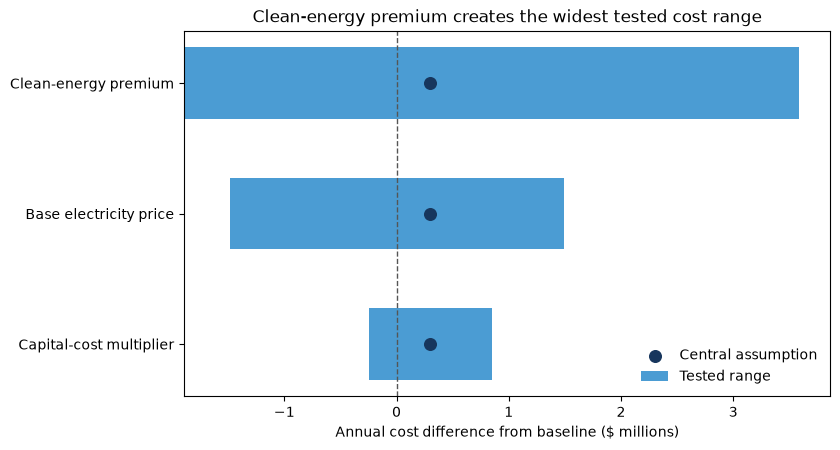

In [7]:
plot_data = sensitivity_summary.copy()

for column in [
    "Low",
    "Central",
    "High",
    "minimum_result_usd",
    "maximum_result_usd",
    "range_usd",
]:
    plot_data[column] /= 1_000_000


plot_data = plot_data.sort_values(
    "range_usd",
    ascending=True,
)

largest_driver = plot_data.loc[
    plot_data["range_usd"].idxmax(),
    "sensitivity_label",
]


fig, ax = plt.subplots(
    figsize=(8.5, 4.8)
)

ax.barh(
    plot_data["sensitivity_label"],
    plot_data["range_usd"],
    left=plot_data["minimum_result_usd"],
    color="#4B9CD3",
    height=0.55,
    label="Tested range",
)

ax.scatter(
    plot_data["Central"],
    plot_data["sensitivity_label"],
    color="#17365D",
    s=70,
    zorder=3,
    label="Central assumption",
)

ax.axvline(
    0,
    color="#555555",
    linewidth=1,
    linestyle="--",
)

ax.set_title(
    f"{largest_driver} creates the widest "
    "tested cost range"
)

ax.set_xlabel(
    "Annual cost difference from baseline "
    "($ millions)"
)

ax.set_ylabel("")

ax.legend(
    frameon=False,
    loc="best",
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

fig.savefig(
    FIGURES / "sensitivity_cost_range.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Direct comparison of the intervention packages

The previous chart compares Efficiency + Clean Procurement with the Grid Baseline. The following analysis directly compares the two intervention packages.

For each sensitivity case, I subtract the annual cost of Efficiency + Clean Procurement from the annual cost of Efficiency + Flexibility + Battery. A positive result means that Efficiency + Clean Procurement is less expensive.

In [8]:
scenario_2 = "Efficiency + Clean Procurement"

scenario_3 = (
    "Efficiency + Flexible Load + Battery"
)


comparison_table = (
    sensitivity
    .pivot_table(
        index=[
            "sensitivity_label",
            "sensitivity_level",
            "input_value",
        ],
        columns="scenario",
        values="total_annual_cost_usd",
        aggfunc="first",
    )
    .reset_index()
)

comparison_table.columns.name = None


comparison_table[
    "scenario_2_savings_vs_scenario_3_usd"
] = (
    comparison_table[scenario_3]
    - comparison_table[scenario_2]
)

comparison_table["scenario_2_cheaper"] = (
    comparison_table[
        "scenario_2_savings_vs_scenario_3_usd"
    ] > 0
)


input_order = [
    "Clean-energy premium",
    "Base electricity price",
    "Capital-cost multiplier",
]

level_order = [
    "Low",
    "Central",
    "High",
]


comparison_table["input_order"] = (
    comparison_table["sensitivity_label"]
    .map({
        label: position
        for position, label in enumerate(input_order)
    })
)

comparison_table["level_order"] = (
    comparison_table["sensitivity_level"]
    .map({
        level: position
        for position, level in enumerate(level_order)
    })
)

comparison_table = (
    comparison_table
    .sort_values([
        "input_order",
        "level_order",
    ])
    .drop(
        columns=[
            "input_order",
            "level_order",
        ]
    )
    .reset_index(drop=True)
)


comparison_table.to_csv(
    TABLES / "scenario_2_vs_scenario_3.csv",
    index=False,
)

In [9]:
comparison_display = comparison_table[
    [
        "sensitivity_label",
        "sensitivity_level",
        "input_value",
        scenario_2,
        scenario_3,
        "scenario_2_savings_vs_scenario_3_usd",
        "scenario_2_cheaper",
    ]
].copy()


for column in [
    scenario_2,
    scenario_3,
    "scenario_2_savings_vs_scenario_3_usd",
]:
    comparison_display[column] = (
        comparison_display[column]
        / 1_000_000
    )


comparison_display = comparison_display.rename(
    columns={
        "sensitivity_label": "Input",
        "sensitivity_level": "Level",
        "input_value": "Input value",
        scenario_2: "Scenario 2 cost ($M)",
        scenario_3: "Scenario 3 cost ($M)",
        "scenario_2_savings_vs_scenario_3_usd": (
            "Scenario 2 cost advantage ($M)"
        ),
        "scenario_2_cheaper": (
            "Scenario 2 cheaper?"
        ),
    }
)


display(
    comparison_display.round(2)
)

,Input,Level,Input value,Scenario 2 cost ($M),Scenario 3 cost ($M),Scenario 2 cost advantage ($M),Scenario 2 cheaper?
0,Clean-energy premium,Low,2.00,62.91,66.96,4.05,True
1,Clean-energy premium,Central,6.00,65.10,68.09,2.99,True
2,Clean-energy premium,High,12.00,68.39,69.79,1.40,True
3,Base electricity price,Low,50.00,51.40,53.94,2.54,True
4,Base electricity price,Central,70.00,65.10,68.09,2.99,True
5,Base electricity price,High,100.00,85.65,89.32,3.67,True
6,Capital-cost multiplier,Low,0.75,64.55,66.86,2.31,True
7,Capital-cost multiplier,Central,1.00,65.10,68.09,2.99,True
8,Capital-cost multiplier,High,1.25,65.65,69.33,3.68,True


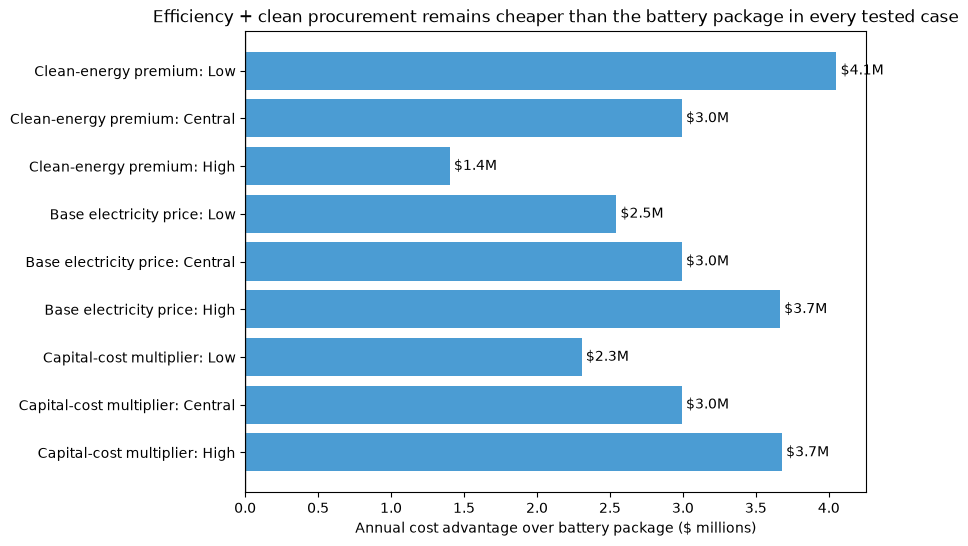

In [10]:
comparison_plot = comparison_table.copy()

comparison_plot[
    "cost_advantage_millions"
] = (
    comparison_plot[
        "scenario_2_savings_vs_scenario_3_usd"
    ]
    / 1_000_000
)

comparison_plot["case_label"] = (
    comparison_plot["sensitivity_label"]
    + ": "
    + comparison_plot["sensitivity_level"]
)

# Reverse the order so the first input appears at the top.
comparison_plot = (
    comparison_plot
    .iloc[::-1]
    .reset_index(drop=True)
)


fig, ax = plt.subplots(
    figsize=(9, 5.8)
)

bars = ax.barh(
    comparison_plot["case_label"],
    comparison_plot["cost_advantage_millions"],
    color="#4B9CD3",
)

ax.axvline(
    0,
    color="#555555",
    linewidth=1,
)

ax.set_title(
    "Efficiency + clean procurement remains cheaper "
    "than the battery package in every tested case"
)

ax.set_xlabel(
    "Annual cost advantage over battery package "
    "($ millions)"
)

ax.set_ylabel("")

ax.bar_label(
    bars,
    labels=[
        f"${value:.1f}M"
        for value in comparison_plot[
            "cost_advantage_millions"
        ]
    ],
    padding=3,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 1]
)

fig.savefig(
    FIGURES / "scenario_2_cost_advantage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Recommendation check

A cost sensitivity test should not automatically select the lowest-cost scenario. The recommendation also considers emissions and peak demand. The relevant questions are whether the clean-procurement package remains reasonably close to baseline cost and whether it remains less costly than the more complex battery package.

In [11]:
comparison = sensitivity.pivot_table(
    index=[
        "sensitivity_input",
        "sensitivity_level",
        "input_value",
    ],
    columns="scenario",
    values="total_annual_cost_usd",
    aggfunc="first",
)


preferred_less_costly_than_battery = (
    comparison[
        "Efficiency + Clean Procurement"
    ]
    < comparison[
        "Efficiency + Flexible Load + Battery"
    ]
).all()


minimum_premium_pct = (
    preferred_cases[
        "cost_difference_from_baseline_pct"
    ].min()
)

maximum_premium_pct = (
    preferred_cases[
        "cost_difference_from_baseline_pct"
    ].max()
)


if preferred_less_costly_than_battery:
    comparison_statement = (
        "Efficiency + Clean Procurement remained "
        "less costly than the efficiency, flexibility, "
        "and battery package in every tested case."
    )
else:
    comparison_statement = (
        "At least one tested case changed the cost "
        "ordering between the two intervention packages."
    )


display(
    Markdown(
        f"""
## Interpretation

Across the nine one-way sensitivity cases, the annual cost difference between Efficiency + Clean Procurement and the baseline ranged from **{minimum_premium_pct:.1f}% to {maximum_premium_pct:.1f}%**. **{largest_driver}** produced the widest tested range.

{comparison_statement}

The results do not show that Efficiency + Clean Procurement is always the lowest-cost option; the baseline remains less expensive under some assumptions. They do show that the clean-procurement package can deliver the largest modeled emissions reduction while remaining financially close to the baseline across a reasonable range of inputs. This supports advancing the strategy to tariff, engineering, and procurement validation rather than making an immediate investment commitment.
"""
    )
)


## Interpretation

Across the nine one-way sensitivity cases, the annual cost difference between Efficiency + Clean Procurement and the baseline ranged from **-2.9% to 5.5%**. **Clean-energy premium** produced the widest tested range.

Efficiency + Clean Procurement remained less costly than the efficiency, flexibility, and battery package in every tested case.

The results do not show that Efficiency + Clean Procurement is always the lowest-cost option; the baseline remains less expensive under some assumptions. They do show that the clean-procurement package can deliver the largest modeled emissions reduction while remaining financially close to the baseline across a reasonable range of inputs. This supports advancing the strategy to tariff, engineering, and procurement validation rather than making an immediate investment commitment.


## Limitations

This analysis changes one assumption at a time and therefore does not represent combinations such as simultaneously high electricity prices, high procurement premiums, and high capital costs. It also does not assign probabilities to the tested values.

The ranges are illustrative rather than forecasts. The analysis does not replace a site-specific tariff study, vendor pricing, interconnection review, or engineering estimate. It tests the robustness of a screening recommendation and identifies which inputs should receive the most attention in the next phase.